# City Complaint Prediction — Full ML Pipeline
### Goal: Predict daily complaint counts per ZIP code using weather, infrastructure, and time data

---

**What this notebook does, step by step:**
1. Load & clean the data
2. Explore the data with charts (EDA)
3. Engineer new features (create smarter inputs)
4. Remove redundant features (Feature Selection)
5. Compress features using PCA
6. Train 6 different ML models
7. Compare them all using R2 score and pick the winner
8. Explain WHY the winner wins with charts

---

## Step 0 — Install & Import Everything

In [1]:
!pip install lightgbm xgboost holidays scikit-learn --quiet

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.pipeline import Pipeline
import lightgbm as lgb
import xgboost as xgb
import holidays

# Make all plots look clean and consistent
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#f9f9f9',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold'
})
SEED = 42
np.random.seed(SEED)
print("All libraries loaded!")

All libraries loaded!


## Step 1 — Load the Data

We load the CSV and immediately check its shape, column types, and missing values.
This is always the first thing in any real ML project — you need to know what you're working with.

In [3]:
df = pd.read_csv("modeling_table_final.csv")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Date range: {df['date'].min()}  to  {df['date'].max()}")
df.info()

Shape: 162,769 rows x 30 columns
Date range: 2020-01-01  to  2024-12-31
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162769 entries, 0 to 162768
Data columns (total 30 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   incident_zip          162769 non-null  int64  
 1   date                  162769 non-null  object 
 2   borough               160951 non-null  object 
 3   request_count         162769 non-null  int64  
 4   complaint_type_count  162769 non-null  int64  
 5   year                  162769 non-null  int64  
 6   month                 162769 non-null  int64  
 7   day_of_week           162769 non-null  int64  
 8   day_of_year           162769 non-null  int64  
 9   season                162769 non-null  int64  
 10  is_weekend            162769 non-null  int64  
 11  is_holiday            162769 non-null  int64  
 12  tmax                  162769 non-null  float64
 13  tmin                  162769 non

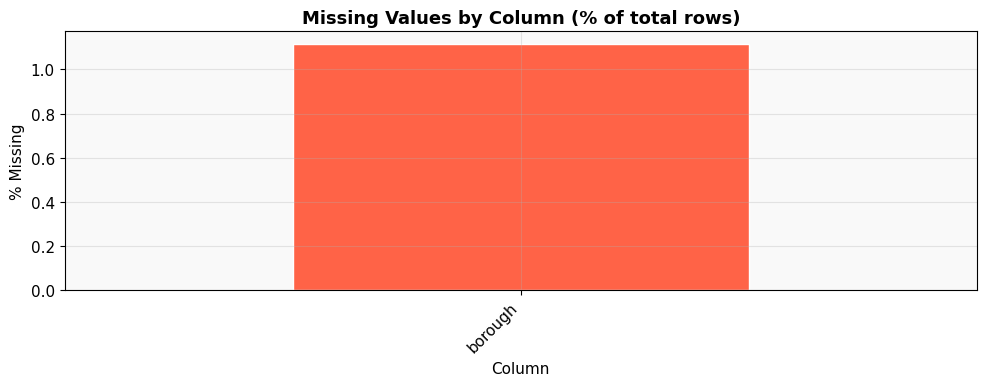

borough    1.11692
dtype: float64


In [4]:
# Check missing values — expressed as percentage so it's more meaningful
null_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]

if len(null_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, 4))
    null_pct.plot(kind='bar', color='tomato', ax=ax, edgecolor='white')
    ax.set_title("Missing Values by Column (% of total rows)")
    ax.set_ylabel("% Missing")
    ax.set_xlabel("Column")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    print(null_pct)
else:
    print("No missing values found!")

In [5]:
# Drop rows where borough is missing — borough is a category, we can't guess it
before = len(df)
df = df.dropna(subset=['borough'])
print(f"Dropped {before - len(df)} rows with missing borough. Remaining: {len(df):,} rows")

# Convert date column to proper datetime format
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)
print("Data sorted by date. Ready for time-series work.")

Dropped 1818 rows with missing borough. Remaining: 160,951 rows
Data sorted by date. Ready for time-series work.


## Step 2 — Exploratory Data Analysis (EDA)

Before building any model, we need to **understand the data visually**.
Charts here answer real questions: Is the target skewed? Does weather matter? Are there weekly patterns?

### 2.1 — What does the target variable look like?

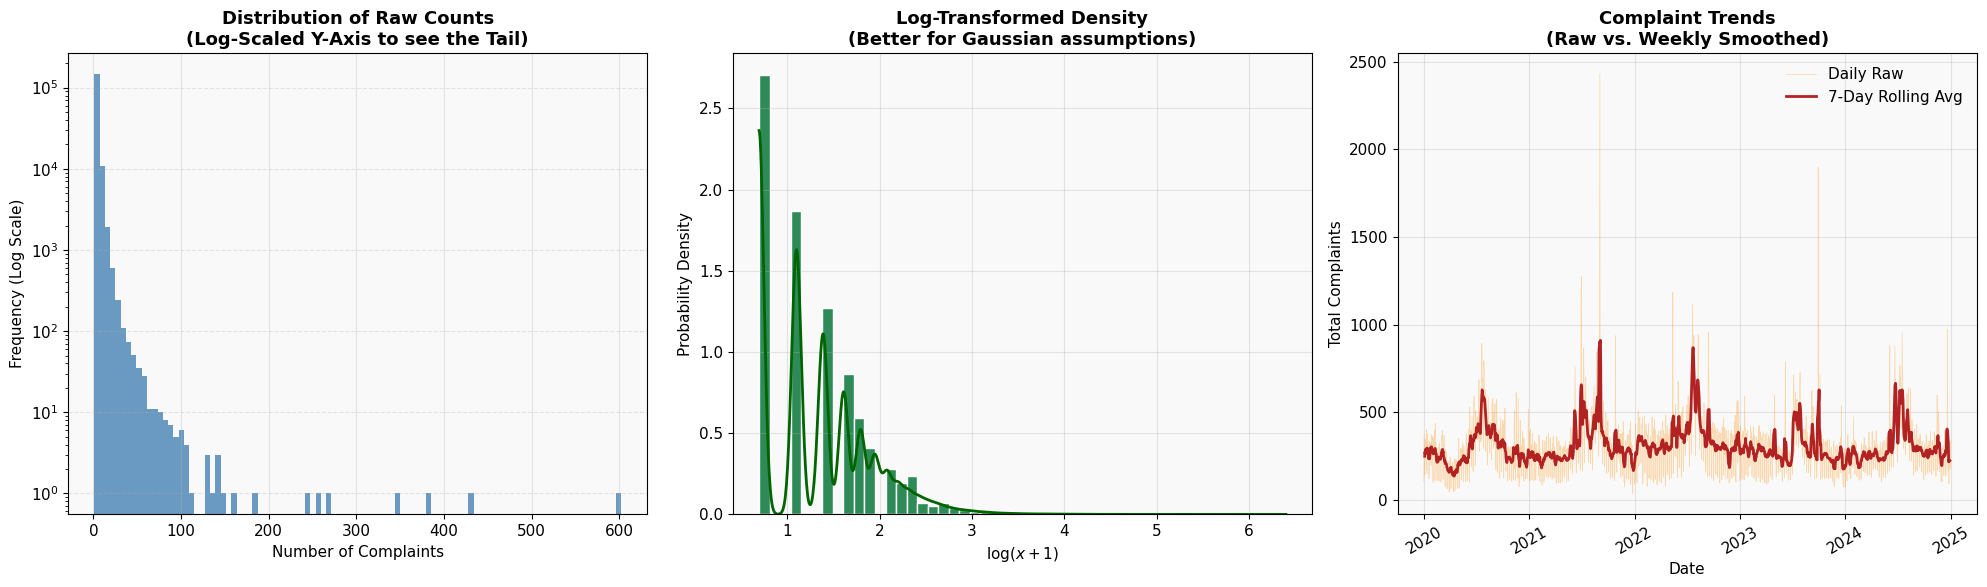

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Setup the figure
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Raw Distribution (Log-Scale Y-Axis)
axes[0].hist(df['request_count'], bins=100, color='steelblue', edgecolor='none', alpha=0.8)
axes[0].set_yscale('log') # This is the game changer for long tails
axes[0].set_title("Distribution of Raw Counts\n(Log-Scaled Y-Axis to see the Tail)")
axes[0].set_xlabel("Number of Complaints")
axes[0].set_ylabel("Frequency (Log Scale)")
axes[0].grid(axis='y', linestyle='--', alpha=0.3)

# 2. Log-Transformed (Better Binning & Density)
log_data = np.log1p(df['request_count'])
axes[1].hist(log_data, bins=50, color='seagreen', edgecolor='white', density=True)
# Overlay a KDE for smoothness
from scipy.stats import gaussian_kde
x_range = np.linspace(log_data.min(), log_data.max(), 1000)
kde = gaussian_kde(log_data)
axes[1].plot(x_range, kde(x_range), color='darkgreen', linewidth=2)
axes[1].set_title("Log-Transformed Density\n(Better for Gaussian assumptions)")
axes[1].set_xlabel("$\log(x + 1)$")
axes[1].set_ylabel("Probability Density")

# 3. Time Series (Smoothing the 'Noise')
daily = df.groupby('date')['request_count'].sum()
# Weekly Rolling Average to highlight the trend vs noise
weekly_rolling = daily.rolling(window=7, center=True).mean()

axes[2].plot(daily.index, daily.values, color='darkorange', linewidth=0.5, alpha=0.3, label='Daily Raw')
axes[2].plot(daily.index, weekly_rolling, color='firebrick', linewidth=2, label='7-Day Rolling Avg')
axes[2].set_title("Complaint Trends\n(Raw vs. Weekly Smoothed)")
axes[2].set_xlabel("Date")
axes[2].set_ylabel("Total Complaints")
axes[2].legend(frameon=False)
plt.setp(axes[2].get_xticklabels(), rotation=30)

plt.tight_layout()
plt.show()

### change  these 3 graphs 1. scaling  2. log and why and data shape change   3. what did we do about the weekly cycles

### 2.2 — Does weather affect complaints?

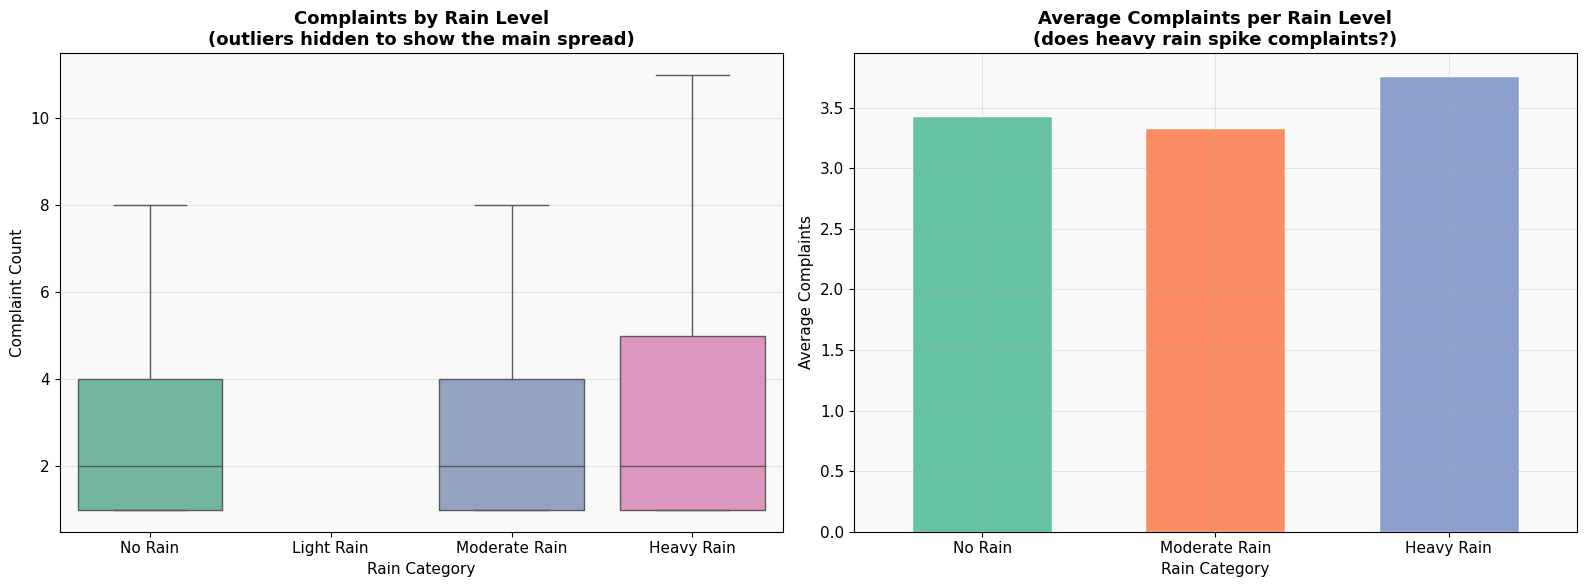

In [7]:
max_prcp = df['prcp'].max()
bins   = [-0.01, 0.01, 0.25, 1.0, max_prcp + 0.1]
labels = ['No Rain', 'Light Rain', 'Moderate Rain', 'Heavy Rain']
df['prcp_cat'] = pd.cut(df['prcp'], bins=bins, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot by rain category
sns.boxplot(x='prcp_cat', y='request_count', data=df,
            showfliers=False, palette='Set2', ax=axes[0])
axes[0].set_title("Complaints by Rain Level\n(outliers hidden to show the main spread)")
axes[0].set_xlabel("Rain Category")
axes[0].set_ylabel("Complaint Count")

# Average complaints per rain category
avg_by_rain = df.groupby('prcp_cat', observed=True)['request_count'].mean()
avg_by_rain.plot(kind='bar', color=['#66c2a5','#fc8d62','#8da0cb','#e78ac3'],
                 ax=axes[1], edgecolor='white', width=0.6)
axes[1].set_title("Average Complaints per Rain Level\n(does heavy rain spike complaints?)")
axes[1].set_xlabel("Rain Category")
axes[1].set_ylabel("Average Complaints")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("plot_02_weather_effect.png", dpi=150, bbox_inches='tight')
plt.show()

### 2.3 — Weekly patterns: which day of week gets the most complaints?

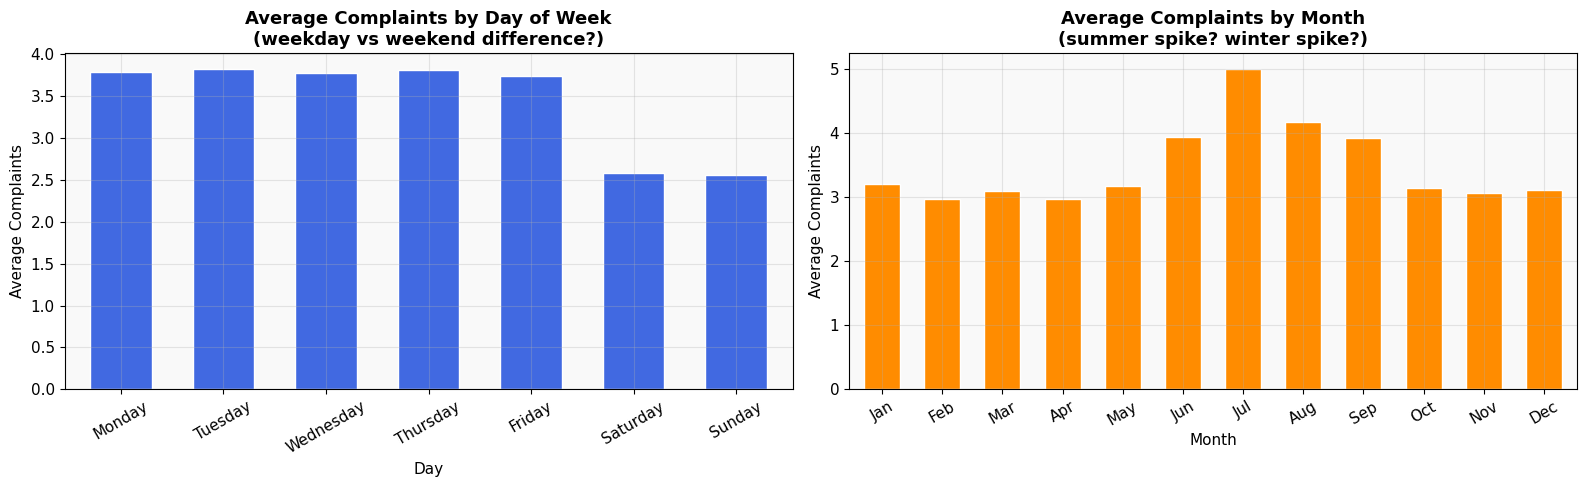

In [8]:
df['day_of_week'] = df['date'].dt.dayofweek
day_names = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Average complaints by day
dow_avg = df.groupby('day_of_week')['request_count'].mean()
dow_avg.index = [day_names[i] for i in dow_avg.index]
dow_avg.plot(kind='bar', color='royalblue', ax=axes[0], edgecolor='white', width=0.6)
axes[0].set_title("Average Complaints by Day of Week\n(weekday vs weekend difference?)")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Average Complaints")
plt.sca(axes[0]); plt.xticks(rotation=30)

# Monthly pattern
df['month'] = df['date'].dt.month
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
month_avg = df.groupby('month')['request_count'].mean()
month_avg.index = [month_names[i-1] for i in month_avg.index]
month_avg.plot(kind='bar', color='darkorange', ax=axes[1], edgecolor='white', width=0.6)
axes[1].set_title("Average Complaints by Month\n(summer spike? winter spike?)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Average Complaints")
plt.sca(axes[1]); plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("plot_03_time_patterns.png", dpi=150, bbox_inches='tight')
plt.show()

### complaints are less on saturays and sundays  and more on rainy days ---- why?

### 2.4 — Borough comparison: which part of the city complains most?

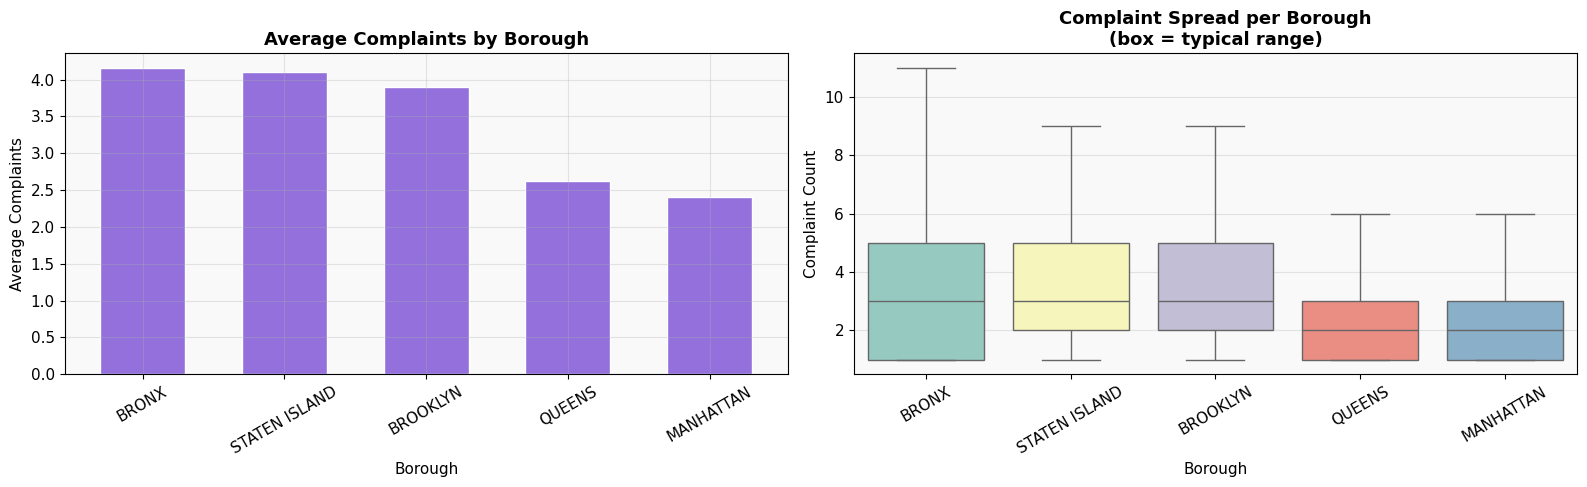

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Average complaints per borough
boro_avg = df.groupby('borough')['request_count'].mean().sort_values(ascending=False)
boro_avg.plot(kind='bar', color='mediumpurple', ax=axes[0], edgecolor='white', width=0.6)
axes[0].set_title("Average Complaints by Borough")
axes[0].set_xlabel("Borough")
axes[0].set_ylabel("Average Complaints")
plt.sca(axes[0]); plt.xticks(rotation=30)

# Boxplot per borough
borough_order = boro_avg.index.tolist()
sns.boxplot(x='borough', y='request_count', data=df,
            order=borough_order, showfliers=False,
            palette='Set3', ax=axes[1])
axes[1].set_title("Complaint Spread per Borough\n(box = typical range)")
axes[1].set_xlabel("Borough")
axes[1].set_ylabel("Complaint Count")
plt.sca(axes[1]); plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("plot_04_borough.png", dpi=150, bbox_inches='tight')
plt.show()

### 2.5 — Does yesterday predict today? (Lag relationship)

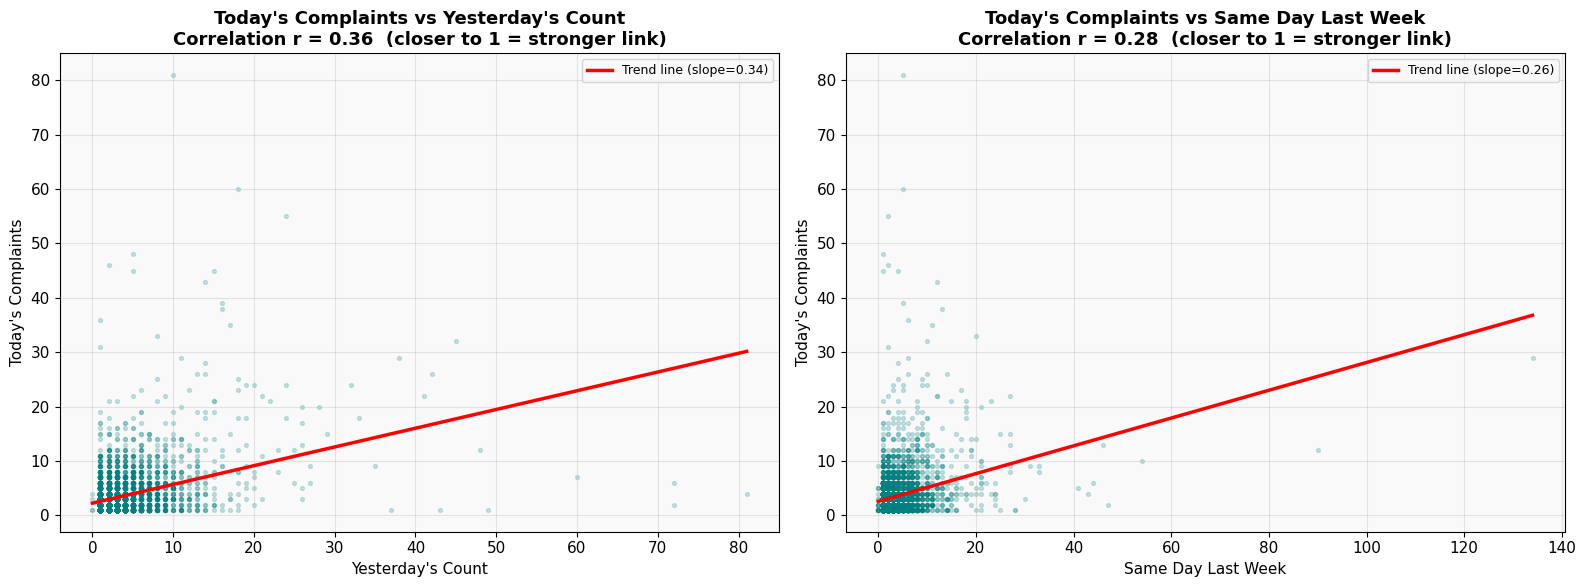

Interpretation: if the slope is steep and points cluster near the red line, the lag feature is VERY useful.But if the slope is flat and points are widely scattered, the lag feature may not add much predictive power.here the dots are wide spread and the slope is not very steep, suggesting that while there is some relationship, it's not strong enough to rely on heavily for predictions.


In [10]:
df_sample = df[['lag_request_1d','lag_request_7d','request_count']].dropna().sample(5000, random_state=SEED)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, col, title_extra in zip(axes,
                                ['lag_request_1d','lag_request_7d'],
                                ["Yesterday's Count","Same Day Last Week"]):
    ax.scatter(df_sample[col], df_sample['request_count'],
               alpha=0.2, color='teal', s=8)
    # Draw a simple trend line
    m, b = np.polyfit(df_sample[col].fillna(0), df_sample['request_count'], 1)
    x_line = np.linspace(df_sample[col].min(), df_sample[col].max(), 200)
    ax.plot(x_line, m*x_line + b, color='red', linewidth=2.5, label=f'Trend line (slope={m:.2f})')
    r = df_sample[[col,'request_count']].dropna().corr().iloc[0,1]
    ax.set_title(f"Today's Complaints vs {title_extra}\nCorrelation r = {r:.2f}  (closer to 1 = stronger link)")
    ax.set_xlabel(title_extra)
    ax.set_ylabel("Today's Complaints")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("plot_05_lag_relationship.png", dpi=150, bbox_inches='tight')
plt.show()
print("Interpretation: if the slope is steep and points cluster near the red line, the lag feature is VERY useful.But if the slope is flat and points are widely scattered, the lag feature may not add much predictive power.here the dots are wide spread and the slope is not very steep, suggesting that while there is some relationship, it's not strong enough to rely on heavily for predictions.")

### 2.6 — Correlation Heatmap: which features move together?

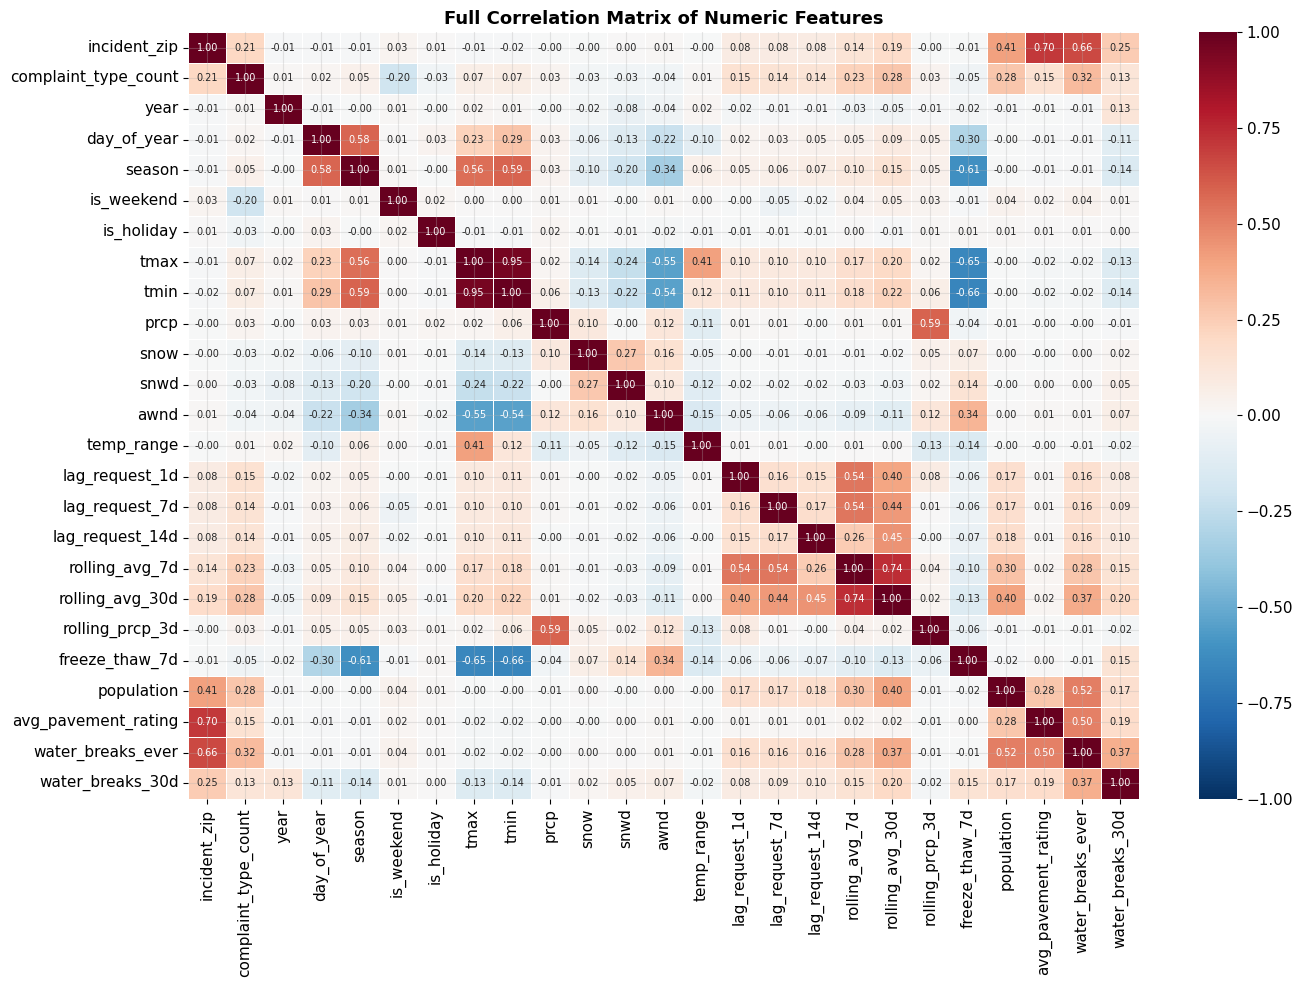

In [11]:
# Use your existing logic to get numeric columns
numeric_df = df.select_dtypes(include=['int64','float64']).drop(columns=['request_count'], errors='ignore')
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(14, 10))

# REMOVED: mask = np.triu(...)
# ADDED: center=0 to make the scale intuitive

sns.heatmap(corr, 
            annot=True, 
            cmap='RdBu_r',   # Red-Blue palette is clearer for full squares
            vmin=-1, 
            vmax=1,
            center=0,        # Forces 0 to be white
            fmt='.2f', 
            linewidths=0.4, 
            ax=ax, 
            annot_kws={'size': 7})

ax.set_title("Full Correlation Matrix of Numeric Features")
plt.tight_layout()

# Save and show
plt.savefig("plot_06_correlation_heatmap_full.png", dpi=150, bbox_inches='tight')
plt.show()

## Step 3 — Feature Engineering

Feature Engineering means **creating new columns** that give the model better information.
Think of it as translating raw data into language the model understands better.

We create:
- **Cyclical time features** (month and day encoded as waves — so Dec and Jan are treated as close together)
- **Temperature range** (instead of keeping both min and max temp separately)
- **Weather x Infrastructure interaction** (rain effect is bigger in areas with old pipes)
- **Trend velocity** (is complaint volume rising or falling lately?)
- **Holiday flag** (complaints behave differently on public holidays)

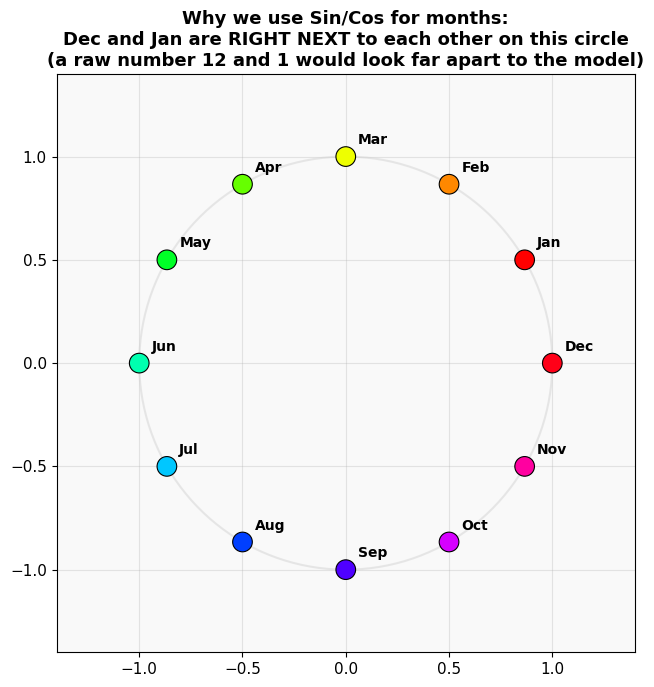

Cyclical features created: month_sin, month_cos, day_sin, day_cos


In [12]:
df_feat = df.copy()

# ── 1. Cyclical encoding of month and day of week ──────────────────────────
# Why: Month 12 and Month 1 are neighbours on a calendar, but if we give the
# model the numbers 12 and 1, it thinks they're far apart. Sin/cos wraps them
# around a circle so the model sees them as close.
df_feat['month_sin'] = np.sin(2 * np.pi * df_feat['month'] / 12)
df_feat['month_cos'] = np.cos(2 * np.pi * df_feat['month'] / 12)
df_feat['day_sin']   = np.sin(2 * np.pi * df_feat['day_of_week'] / 7)
df_feat['day_cos']   = np.cos(2 * np.pi * df_feat['day_of_week'] / 7)

# Visualize: show the circle wrapping effect for months
fig, ax = plt.subplots(figsize=(7, 7))
months = np.arange(1, 13)
s = np.sin(2 * np.pi * months / 12)
c = np.cos(2 * np.pi * months / 12)
ax.scatter(c, s, s=200, c=months, cmap='hsv', zorder=5, edgecolors='black', linewidths=0.8)
for i, m in enumerate(months):
    ax.annotate(month_names[m-1], (c[i]+0.06, s[i]+0.06), fontsize=10, fontweight='bold')
theta = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(theta), np.sin(theta), 'lightgray', alpha=0.5)
ax.set_aspect('equal')
ax.set_title("Why we use Sin/Cos for months:\nDec and Jan are RIGHT NEXT to each other on this circle\n(a raw number 12 and 1 would look far apart to the model)")
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
plt.tight_layout()
plt.savefig("plot_07_cyclical_encoding.png", dpi=150, bbox_inches='tight')
plt.show()

print("Cyclical features created: month_sin, month_cos, day_sin, day_cos")

In [13]:
# ── 2. Temperature Range ──────────────────────────────────────────────────
# tmax and tmin together are redundant — they tell the model almost the same thing.
# temp_range (the difference) tells us: "how extreme was the day?"
# This keeps the useful info and removes the duplication.
if 'tmax' in df_feat.columns and 'tmin' in df_feat.columns:
    df_feat['temp_range'] = df_feat['tmax'] - df_feat['tmin']
    print(f"temp_range created. Sample stats: mean={df_feat['temp_range'].mean():.1f}, max={df_feat['temp_range'].max():.1f}")

# ── 3. Holiday flag ────────────────────────────────────────────────────────
years = df_feat['date'].dt.year.unique().tolist()
us_hols = holidays.UnitedStates(years=years)
df_feat['is_holiday'] = df_feat['date'].isin(us_hols).astype(int)
n_holiday_days = df_feat['is_holiday'].sum()
print(f"Holiday flag created. Found {n_holiday_days} holiday-day records.")

# ── 4. Weather x Infrastructure Interaction ───────────────────────────────
# When it rains heavily AND infrastructure is already weak (lots of past water breaks),
# complaints spike disproportionately. Multiplying these two captures that combined effect.
if 'prcp' in df_feat.columns and 'water_breaks_ever' in df_feat.columns:
    df_feat['rain_x_infra'] = df_feat['prcp'] * df_feat['water_breaks_ever']
    print("rain_x_infra interaction feature created.")

# ── 5. Trend Velocity (short-term vs long-term average) ───────────────────
# Is the complaint trend RISING or FALLING compared to last month?
# Positive velocity = things are getting worse. Negative = stabilising.
if 'rolling_avg_7d' in df_feat.columns:
    df_feat_sorted = df_feat.sort_values(['incident_zip','date'])
    rolling_30 = (df_feat_sorted.groupby('incident_zip')['request_count']
                  .transform(lambda x: x.shift(1).rolling(30, min_periods=10).mean()))
    df_feat['rolling_avg_30d'] = rolling_30.values
    df_feat['trend_velocity']  = df_feat['rolling_avg_7d'] - df_feat['rolling_avg_30d']
    print("trend_velocity feature created (7-day avg minus 30-day avg).")

print("\nAll feature engineering done!")
print(f"Dataset now has {df_feat.shape[1]} columns (was {df.shape[1]})")

temp_range created. Sample stats: mean=7.8, max=27.6
Holiday flag created. Found 4556 holiday-day records.
rain_x_infra interaction feature created.
trend_velocity feature created (7-day avg minus 30-day avg).

All feature engineering done!
Dataset now has 37 columns (was 31)


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160951 entries, 0 to 160950
Data columns (total 31 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   incident_zip          160951 non-null  int64         
 1   date                  160951 non-null  datetime64[ns]
 2   borough               160951 non-null  object        
 3   request_count         160951 non-null  int64         
 4   complaint_type_count  160951 non-null  int64         
 5   year                  160951 non-null  int64         
 6   month                 160951 non-null  int32         
 7   day_of_week           160951 non-null  int32         
 8   day_of_year           160951 non-null  int64         
 9   season                160951 non-null  int64         
 10  is_weekend            160951 non-null  int64         
 11  is_holiday            160951 non-null  int64         
 12  tmax                  160951 non-null  float64       
 13 

## Step 4 — Feature Selection (Removing Redundant Columns)

Too many features can actually HURT a model — especially if features are highly correlated
(they carry the same information and confuse the model).

We drop:
- **tmax and tmin** — replaced by temp_range (one column doing the same job)
- **day_of_year** — almost the same as month, creates confusion
- **prcp_cat** — this was just an analysis column, not a real feature
- **request_count_log** — we'll create this fresh later; don't want double-counting


In [15]:
# Decide what to drop — with clear plain-English reasons
drop_cols = {
    'tmax':              'Replaced by temp_range — keeping both is duplication',
    'tmin':              'Replaced by temp_range — keeping both is duplication',
    'day_of_year':       'Almost identical to month — causes confusion (very high correlation)',
    'prcp_cat':          'Was only used for charts — not a real feature',
    'request_count_log': 'Will recreate this cleanly as the target column',
}

df_clean = df_feat.copy()
actually_dropped = []
for col, reason in drop_cols.items():
    if col in df_clean.columns:
        df_clean.drop(columns=[col], inplace=True)
        actually_dropped.append(col)
        print(f"  Dropped '{col}' — {reason}")

print(f"\nFeatures before selection: {df_feat.shape[1]}")
print(f"Features after selection:  {df_clean.shape[1]}")
print(f"Dropped {len(actually_dropped)} columns")

  Dropped 'tmax' — Replaced by temp_range — keeping both is duplication
  Dropped 'tmin' — Replaced by temp_range — keeping both is duplication
  Dropped 'day_of_year' — Almost identical to month — causes confusion (very high correlation)
  Dropped 'prcp_cat' — Was only used for charts — not a real feature

Features before selection: 37
Features after selection:  33
Dropped 4 columns


In [16]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160951 entries, 0 to 160950
Data columns (total 33 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   incident_zip          160951 non-null  int64         
 1   date                  160951 non-null  datetime64[ns]
 2   borough               160951 non-null  object        
 3   request_count         160951 non-null  int64         
 4   complaint_type_count  160951 non-null  int64         
 5   year                  160951 non-null  int64         
 6   month                 160951 non-null  int32         
 7   day_of_week           160951 non-null  int32         
 8   season                160951 non-null  int64         
 9   is_weekend            160951 non-null  int64         
 10  is_holiday            160951 non-null  int64         
 11  prcp                  160951 non-null  float64       
 12  snow                  160951 non-null  float64       
 13 

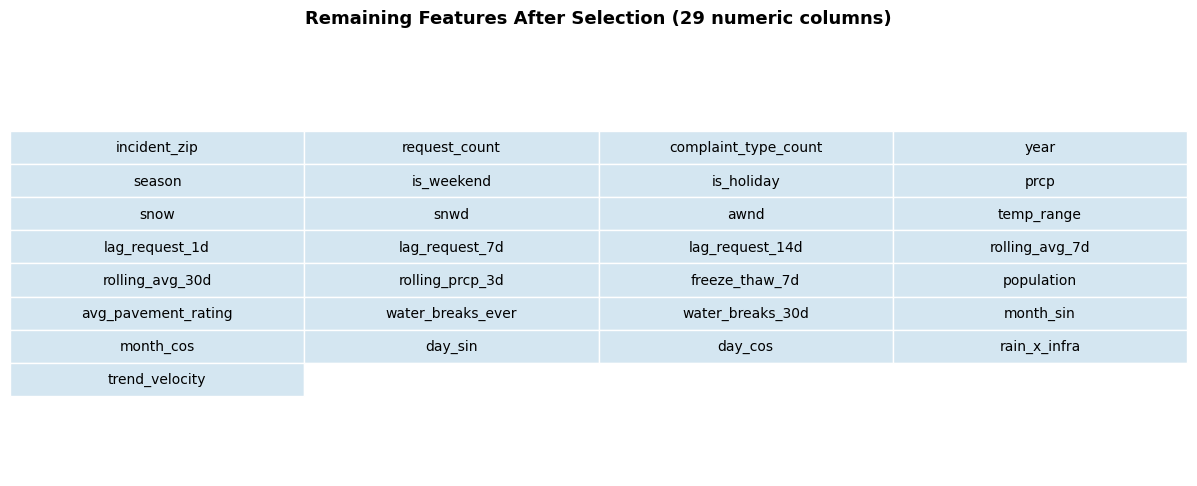

In [17]:
# Show remaining features as a clear visual checklist
remaining_numeric = df_clean.select_dtypes(include=['int64','float64']).columns.tolist()

fig, ax = plt.subplots(figsize=(12, 5))
ax.axis('off')

cols_per_row = 4
rows = [remaining_numeric[i:i+cols_per_row] for i in range(0, len(remaining_numeric), cols_per_row)]
table_data = rows if len(rows[-1]) == cols_per_row else rows
table = ax.table(
    cellText=[[c for c in row] + ['']*(cols_per_row - len(row)) for row in rows],
    loc='center', cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)
for (r, c), cell in table.get_celld().items():
    if table[r,c].get_text().get_text():
        cell.set_facecolor('#d4e6f1')
    else:
        cell.set_facecolor('white')
    cell.set_edgecolor('white')

ax.set_title(f"Remaining Features After Selection ({len(remaining_numeric)} numeric columns)", 
             fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig("plot_08_remaining_features.png", dpi=150, bbox_inches='tight')
plt.show()

## Step 5 — Log-Transform the Target Variable

The complaint count has a long right tail (a few ZIP codes have extremely high counts).
Taking the log makes the distribution more balanced, which helps models learn better.

log(complaints + 1) is used — the "+1" just prevents log(0) from being undefined.

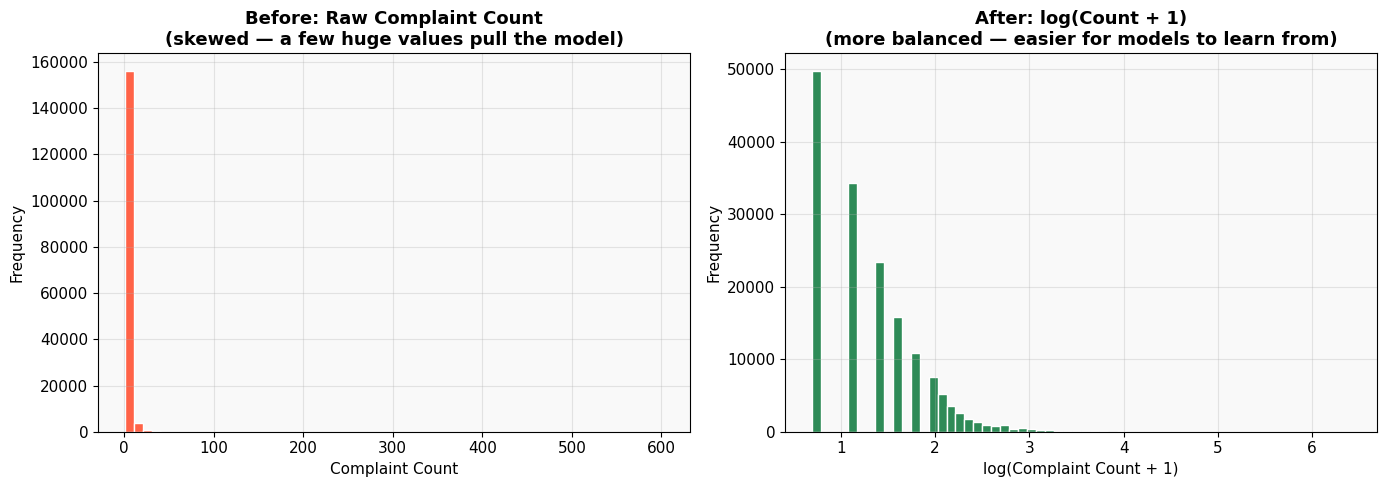

Target column 'target' = log1p(request_count) created.


In [18]:
df_clean['target'] = np.log1p(df_clean['request_count'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_clean['request_count'], bins=60, color='tomato', edgecolor='white')
axes[0].set_title("Before: Raw Complaint Count\n(skewed — a few huge values pull the model)")
axes[0].set_xlabel("Complaint Count")
axes[0].set_ylabel("Frequency")

axes[1].hist(df_clean['target'], bins=60, color='seagreen', edgecolor='white')
axes[1].set_title("After: log(Count + 1)\n(more balanced — easier for models to learn from)")
axes[1].set_xlabel("log(Complaint Count + 1)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("plot_09_log_transform.png", dpi=150, bbox_inches='tight')
plt.show()
print("Target column 'target' = log1p(request_count) created.")

## Step 6 — Prepare the Feature Matrix & Train/Test Split

### Why we use Time-Series Split (not random split)
In a regular ML project you might randomly shuffle and split data.
But here the data is TIME-BASED — you cannot use tomorrow's data to predict today.

Time-Series Split creates 5 windows where training always comes BEFORE testing.
This is the honest, real-world way to evaluate time-series models.

In [19]:
# Encode incident_zip as integer (required by most sklearn models)
le = LabelEncoder()
df_clean['zip_encoded'] = le.fit_transform(df_clean['incident_zip'].astype(str))

# Define what goes INTO the model (X) and what we're predicting (y)
DROP_FROM_X = ['request_count', 'target', 'date', 'borough', 'incident_zip', 'prcp_cat']
feature_cols = [c for c in df_clean.columns 
                if c not in DROP_FROM_X 
                and df_clean[c].dtype in ['int64','float64','float32','int32']]

X = df_clean[feature_cols].copy()
y = df_clean['target'].copy()   # log-transformed complaints

# Handle any remaining nulls by filling with column median
X = X.fillna(X.median())

print(f"Feature matrix X: {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"Target y: {y.shape[0]:,} values")
print(f"\nFeatures used:\n{list(X.columns)}")

Feature matrix X: 160,951 rows x 30 features
Target y: 160,951 values

Features used:
['complaint_type_count', 'year', 'month', 'day_of_week', 'season', 'is_weekend', 'is_holiday', 'prcp', 'snow', 'snwd', 'awnd', 'temp_range', 'lag_request_1d', 'lag_request_7d', 'lag_request_14d', 'rolling_avg_7d', 'rolling_avg_30d', 'rolling_prcp_3d', 'freeze_thaw_7d', 'population', 'avg_pavement_rating', 'water_breaks_ever', 'water_breaks_30d', 'month_sin', 'month_cos', 'day_sin', 'day_cos', 'rain_x_infra', 'trend_velocity', 'zip_encoded']


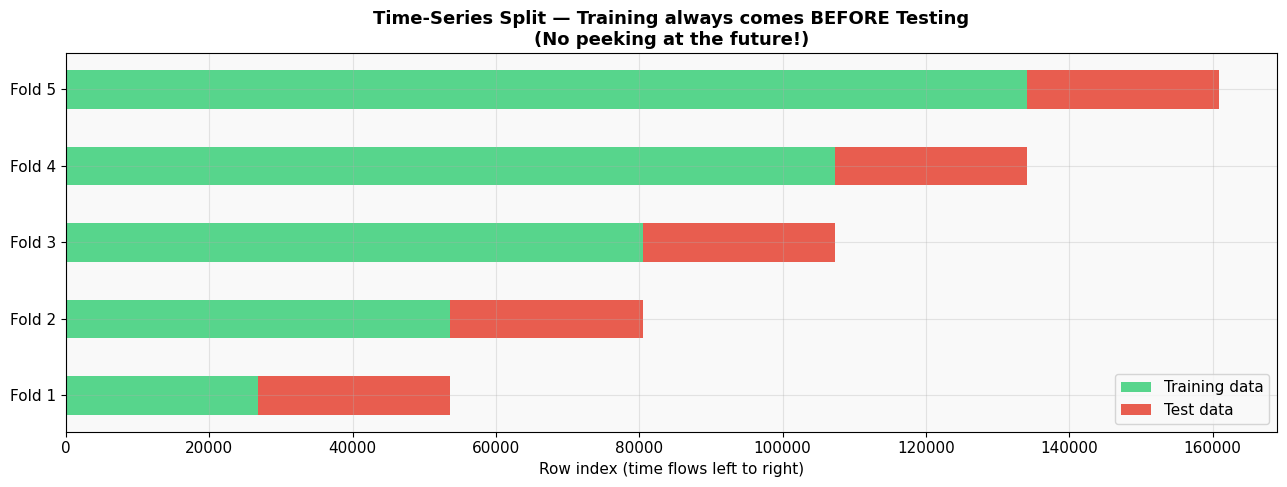

In [20]:
# Visualise TimeSeriesSplit so it's clear what's happening
tscv = TimeSeriesSplit(n_splits=5)

fig, ax = plt.subplots(figsize=(13, 5))
palette = ['#2ecc71', '#e74c3c']

for fold, (tr_idx, te_idx) in enumerate(tscv.split(X)):
    ax.barh(fold, len(tr_idx), left=tr_idx[0], height=0.5,
            color=palette[0], alpha=0.8, label='Training data' if fold==0 else '')
    ax.barh(fold, len(te_idx), left=te_idx[0], height=0.5,
            color=palette[1], alpha=0.9, label='Test data' if fold==0 else '')

ax.set_yticks(range(5))
ax.set_yticklabels([f'Fold {i+1}' for i in range(5)])
ax.set_xlabel('Row index (time flows left to right)')
ax.set_title("Time-Series Split — Training always comes BEFORE Testing\n(No peeking at the future!)")
ax.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.savefig("plot_10_timeseries_split.png", dpi=150, bbox_inches='tight')
plt.show()

In [21]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Grab ALL numeric features (Drop IDs, dates, and the target)
# Make sure you are using your clean dataframe that had redundant columns removed
numeric_cols = df_feat.select_dtypes(include=['int64', 'float64']).columns.tolist()

# The columns we DO NOT want the model to train on
cols_to_drop = ['incident_zip', 'request_count', 'request_count_log'] 

# Keep only the valid training features
features_to_use = [col for col in numeric_cols if col not in cols_to_drop]

# 2. Set up X (All Features) and y (LOG-TRANSFORMED Target)
X_full = df_feat[features_to_use].fillna(0) # Ensure no missing values crash the model
y_full_log = np.log1p(df_feat['request_count']) # <-- THIS IS THE SECRET SAUCE

print(f"Training on {X_full.shape[1]} features...")

# 3. Use YOUR exact TimeSeriesSplit logic
tscv = TimeSeriesSplit(n_splits=5)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

r2_scores = []
mae_scores = []

print("🌲 Running 5-Fold Time-Series Cross Validation...\n")

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_full)):
    
    # Slice the data
    X_train_fold, X_test_fold = X_full.iloc[train_idx], X_full.iloc[test_idx]
    y_train_fold, y_test_fold = y_full_log.iloc[train_idx], y_full_log.iloc[test_idx]
    
    # Train and Predict (Predicting the LOG values)
    rf_model.fit(X_train_fold, y_train_fold)
    preds_log = rf_model.predict(X_test_fold)
    
    # Grade the fold (using the log values for R2)
    r2 = r2_score(y_test_fold, preds_log)
    
    # For MAE, we want to see actual complaints, so we reverse the log (expm1)
    preds_actual = np.expm1(preds_log)
    y_test_actual = np.expm1(y_test_fold)
    mae = mean_absolute_error(y_test_actual, preds_actual)
    
    r2_scores.append(r2)
    mae_scores.append(mae)
    
    print(f"Fold {fold+1} Exam -> R² (Log): {r2: >6.3f}  |  MAE (Actual): {mae:.2f}")

print("\n" + "="*35)
print("🏆 TRUE BASELINE SCORES 🏆")
print("="*35)
print(f"Average R²:  {np.mean(r2_scores):.4f}")
print(f"Average MAE: {np.mean(mae_scores):.2f} complaints")
print("="*35)

Training on 30 features...
🌲 Running 5-Fold Time-Series Cross Validation...

Fold 1 Exam -> R² (Log):  0.566  |  MAE (Actual): 1.64
Fold 2 Exam -> R² (Log):  0.555  |  MAE (Actual): 1.52
Fold 3 Exam -> R² (Log):  0.565  |  MAE (Actual): 1.51
Fold 4 Exam -> R² (Log):  0.587  |  MAE (Actual): 1.31
Fold 5 Exam -> R² (Log):  0.600  |  MAE (Actual): 1.37

🏆 TRUE BASELINE SCORES 🏆
Average R²:  0.5747
Average MAE: 1.47 complaints


## Step 7 — PCA (Principal Component Analysis)

PCA is a technique that **compresses** many features into fewer "summary" features.
Think of it like summarising a 20-page report into 5 bullet points — you keep most
of the important information but reduce the clutter.

We use PCA here to:
1. See if we CAN compress the features without losing much info
2. Use the compressed version as one of the model variants we compare

But since we have used a tree based model and PCA works on distances it is not suitable to do pca on this data ...
we have done it earlier but as it stands pca gave terrible results and more errors so we will skip this entirely 

### add lag 1 day and Lag 7 day and trying Xgboost (as an alternative to random forest just to check if it makes any difference)

In [22]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error
from lightgbm import LGBMRegressor # The new champion engine

print("1. Engineering new Time-Series Features...")

# 1. Sort the data to make sure time is flowing correctly
df_feat = df_feat.sort_values(by=['incident_zip', 'date'])

# 2. Add the "Magic" Columns (Grouping by ZIP code so we don't mix neighborhoods)
# What happened exactly yesterday?
df_feat['lag_1d'] = df_feat.groupby('incident_zip')['request_count'].shift(1)
# What happened exactly on this day last week?
df_feat['lag_7d'] = df_feat.groupby('incident_zip')['request_count'].shift(7)

# 3. Clean up the new dataset
# Dropping the first 7 days for each ZIP code because they won't have a "last week" to look at
df_enhanced = df_feat.dropna(subset=['lag_1d', 'lag_7d']).copy()

# 4. Prepare for ML
numeric_cols = df_enhanced.select_dtypes(include=['int64', 'float64']).columns.tolist()
cols_to_drop = ['incident_zip', 'request_count', 'request_count_log'] 
features_to_use = [col for col in numeric_cols if col not in cols_to_drop]

X_new = df_enhanced[features_to_use].fillna(0)
y_new_log = np.log1p(df_enhanced['request_count'])

print(f"Training on {X_new.shape[1]} features (including new Lags)...")

# 5. Set up the new Engine (LightGBM)
tscv = TimeSeriesSplit(n_splits=5)
lgbm_model = LGBMRegressor(n_estimators=150, random_state=42, n_jobs=-1, verbose=-1)

r2_scores = []
mae_scores = []

print("\n🚀 Running LightGBM with Enhanced Features...\n")

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_new)):
    X_train_fold, X_test_fold = X_new.iloc[train_idx], X_new.iloc[test_idx]
    y_train_fold, y_test_fold = y_new_log.iloc[train_idx], y_new_log.iloc[test_idx]
    
    # Train and Predict
    lgbm_model.fit(X_train_fold, y_train_fold)
    preds_log = lgbm_model.predict(X_test_fold)
    
    # Grade
    r2 = r2_score(y_test_fold, preds_log)
    preds_actual = np.expm1(preds_log)
    y_test_actual = np.expm1(y_test_fold)
    mae = mean_absolute_error(y_test_actual, preds_actual)
    
    r2_scores.append(r2)
    mae_scores.append(mae)
    
    print(f"Fold {fold+1} Exam -> R² (Log): {r2: >6.3f}  |  MAE (Actual): {mae:.2f}")

print("\n" + "="*35)
print("🏆 NEW LIGHTGBM SCORES 🏆")
print("="*35)
print(f"Average R²:  {np.mean(r2_scores):.4f}")
print(f"Average MAE: {np.mean(mae_scores):.2f} complaints")
print("="*35)

1. Engineering new Time-Series Features...
Training on 32 features (including new Lags)...

🚀 Running LightGBM with Enhanced Features...

Fold 1 Exam -> R² (Log):  0.500  |  MAE (Actual): 1.35
Fold 2 Exam -> R² (Log):  0.559  |  MAE (Actual): 1.89
Fold 3 Exam -> R² (Log):  0.562  |  MAE (Actual): 1.55
Fold 4 Exam -> R² (Log):  0.573  |  MAE (Actual): 1.52
Fold 5 Exam -> R² (Log):  0.580  |  MAE (Actual): 1.47

🏆 NEW LIGHTGBM SCORES 🏆
Average R²:  0.5548
Average MAE: 1.56 complaints


### trying to imporve a model by adding rolling averages but didnt work

In [23]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

print("1. Fixing Data Leakage in Advanced Features...")

df_feat['date'] = pd.to_datetime(df_feat['date'])
df_feat = df_feat.sort_values(by=['incident_zip', 'date'])

# 1. Calendar Features (Safe)
df_feat['day_of_week'] = df_feat['date'].dt.dayofweek
df_feat['is_weekend'] = df_feat['day_of_week'].isin([5, 6]).astype(int)
df_feat['month'] = df_feat['date'].dt.month

# 2. Volatility Features (FIXED WITH .shift(1))
# Now it strictly calculates the standard deviation of the PAST 7 days
df_feat['rolling_std_7d_safe'] = df_feat.groupby('incident_zip')['request_count'].transform(
    lambda x: x.shift(1).rolling(window=7, min_periods=1).std()
).fillna(0)

# The 3-day average of the PAST 3 days
rolling_3d_safe = df_feat.groupby('incident_zip')['request_count'].transform(
    lambda x: x.shift(1).rolling(window=3, min_periods=1).mean()
).fillna(0)

# We also need to ensure rolling_avg_7d is safe! (Assuming it was already in your df)
# Let's forcefully recalculate a safe 7-day average just to be 100% sure there's no leak
rolling_7d_safe = df_feat.groupby('incident_zip')['request_count'].transform(
    lambda x: x.shift(1).rolling(window=7, min_periods=1).mean()
).fillna(0)

df_feat['spike_ratio_safe'] = rolling_3d_safe / (rolling_7d_safe + 0.01)

# 3. Prepare the Dataset
numeric_cols = df_feat.select_dtypes(include=['int32', 'int64', 'float64']).columns.tolist()

# CRITICAL: We must drop any old leaking columns to ensure purity
cols_to_drop = ['incident_zip', 'request_count', 'request_count_log', 
                'lag_1d', 'lag_7d', 'rolling_std_7d', 'spike_ratio', 'rolling_avg_7d'] 
                
features_to_use = [col for col in numeric_cols if col not in cols_to_drop]

X_safe = df_feat[features_to_use].fillna(0)
y_safe_log = np.log1p(df_feat['request_count'])

print(f"Training on {X_safe.shape[1]} strictly LEAK-PROOF features...")

# 4. The True Test
tscv = TimeSeriesSplit(n_splits=5)
rf_model_safe = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

r2_scores = []
mae_scores = []

print("\n🌲 Running Random Forest (No Cheating Allowed)...\n")

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_safe)):
    X_train_fold, X_test_fold = X_safe.iloc[train_idx], X_safe.iloc[test_idx]
    y_train_fold, y_test_fold = y_safe_log.iloc[train_idx], y_safe_log.iloc[test_idx]
    
    rf_model_safe.fit(X_train_fold, y_train_fold)
    preds_log = rf_model_safe.predict(X_test_fold)
    
    r2 = r2_score(y_test_fold, preds_log)
    preds_actual = np.expm1(preds_log)
    y_test_actual = np.expm1(y_test_fold)
    mae = mean_absolute_error(y_test_actual, preds_actual)
    
    r2_scores.append(r2)
    mae_scores.append(mae)
    
    print(f"Fold {fold+1} Exam -> R² (Log): {r2: >6.3f}  |  MAE (Actual): {mae:.2f}")

print("\n" + "="*35)
print("🏆 TRUE ENHANCED SCORES (NO LEAKS) 🏆")
print("="*35)
print(f"Average R²:  {np.mean(r2_scores):.4f}")
print(f"Average MAE: {np.mean(mae_scores):.2f} complaints")
print("="*35)

1. Fixing Data Leakage in Advanced Features...
Training on 33 strictly LEAK-PROOF features...

🌲 Running Random Forest (No Cheating Allowed)...

Fold 1 Exam -> R² (Log):  0.504  |  MAE (Actual): 1.37
Fold 2 Exam -> R² (Log):  0.565  |  MAE (Actual): 1.90
Fold 3 Exam -> R² (Log):  0.539  |  MAE (Actual): 1.61
Fold 4 Exam -> R² (Log):  0.532  |  MAE (Actual): 1.63
Fold 5 Exam -> R² (Log):  0.557  |  MAE (Actual): 1.53

🏆 TRUE ENHANCED SCORES (NO LEAKS) 🏆
Average R²:  0.5393
Average MAE: 1.61 complaints


### trying to improve model by adding a new column about a zipwsise average complaint upto certain yesterday based on the fold tht we have made in timesplit to prevent data leak

In [24]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

print("1. Engineering the Leak-Proof 'Historical Zip Average'...")

# 1. Ensure time is flowing correctly
df_feat['date'] = pd.to_datetime(df_feat['date'])
df_feat = df_feat.sort_values(by=['incident_zip', 'date'])

# 2. THE NEW FEATURE: All-time average up to yesterday
df_feat['historical_zip_avg'] = df_feat.groupby('incident_zip')['request_count'].transform(
    lambda x: x.shift(1).expanding().mean()
).fillna(0) # Fill the very first day with 0 since there is no history yet

# 3. Clean up the features (Make absolutely sure we drop the old leaky columns!)
experimental_cols = ['day_of_week', 'is_weekend', 'month', 'rolling_std_7d_safe', 
                     'spike_ratio_safe', 'lag_1d', 'lag_7d', 'rolling_std_7d', 'spike_ratio']
numeric_cols = df_feat.select_dtypes(include=['int32', 'int64', 'float64']).columns.tolist()

# Drop the target, IDs, and the bad experimental columns from earlier
cols_to_drop = ['incident_zip', 'request_count', 'request_count_log'] + experimental_cols
features_to_use = [col for col in numeric_cols if col not in cols_to_drop and col in df_feat.columns]

X_hist = df_feat[features_to_use].fillna(0)
y_hist_log = np.log1p(df_feat['request_count'])

print(f"Training on {X_hist.shape[1]} features (including the new Historical Zip Avg)...")

# 4. Run the True Test
tscv = TimeSeriesSplit(n_splits=5)
rf_model_hist = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

r2_scores = []
mae_scores = []

print("\n🌲 Running Random Forest with Historical Average...\n")

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_hist)):
    X_train_fold, X_test_fold = X_hist.iloc[train_idx], X_hist.iloc[test_idx]
    y_train_fold, y_test_fold = y_hist_log.iloc[train_idx], y_hist_log.iloc[test_idx]
    
    rf_model_hist.fit(X_train_fold, y_train_fold)
    preds_log = rf_model_hist.predict(X_test_fold)
    
    r2 = r2_score(y_test_fold, preds_log)
    preds_actual = np.expm1(preds_log)
    y_test_actual = np.expm1(y_test_fold)
    mae = mean_absolute_error(y_test_actual, preds_actual)
    
    r2_scores.append(r2)
    mae_scores.append(mae)
    
    print(f"Fold {fold+1} Exam -> R² (Log): {r2: >6.3f}  |  MAE (Actual): {mae:.2f}")

print("\n" + "="*35)
print("🏆 NEW SCORES (HISTORICAL AVG) 🏆")
print("="*35)
print(f"Average R²:  {np.mean(r2_scores):.4f}")
print(f"Average MAE: {np.mean(mae_scores):.2f} complaints")
print("="*35)

1. Engineering the Leak-Proof 'Historical Zip Average'...
Training on 30 features (including the new Historical Zip Avg)...

🌲 Running Random Forest with Historical Average...

Fold 1 Exam -> R² (Log):  0.517  |  MAE (Actual): 1.38
Fold 2 Exam -> R² (Log):  0.566  |  MAE (Actual): 1.92
Fold 3 Exam -> R² (Log):  0.547  |  MAE (Actual): 1.59
Fold 4 Exam -> R² (Log):  0.535  |  MAE (Actual): 1.61
Fold 5 Exam -> R² (Log):  0.555  |  MAE (Actual): 1.54

🏆 NEW SCORES (HISTORICAL AVG) 🏆
Average R²:  0.5440
Average MAE: 1.61 complaints


## since no step is improving the model we will squeeze that last 1 3 percent of improvement from hyperparameter tuning and be done with it 

In [25]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

print("1. Reverting to the True Champion Dataset (The 0.58 Baseline)...\n")

# 1. Strip away all experimental/leaky columns
experimental_cols = ['day_of_week', 'is_weekend', 'month', 'rolling_std_7d_safe', 
                     'spike_ratio_safe', 'lag_1d', 'lag_7d', 'rolling_std_7d', 'spike_ratio', 'historical_zip_avg']

numeric_cols = df_feat.select_dtypes(include=['int32', 'int64', 'float64']).columns.tolist()
cols_to_drop = ['incident_zip', 'request_count', 'request_count_log'] + experimental_cols
features_to_use = [col for col in numeric_cols if col not in cols_to_drop and col in df_feat.columns]

X_final = df_feat[features_to_use].fillna(0)
y_final_log = np.log1p(df_feat['request_count'])

print(f"Locked in {X_final.shape[1]} features. Starting Hyperparameter Tuning...\n")

# 2. Define the Tuning Options (The "Dials" we want to turn)
param_distributions = {
    'n_estimators': [100, 200],          # How many trees to build? (More is usually better but slower)
    'max_depth': [None, 15, 25, 35],     # How deep can the trees grow? (Restricting this prevents overfitting)
    'min_samples_split': [2, 5, 10],     # Minimum samples required to split a node
    'min_samples_leaf': [1, 2, 4]        # Minimum samples required at the very end of a branch
}

# 3. Set up the Engine and the strict Time-Series rules
rf = RandomForestRegressor(random_state=42, n_jobs=-1)
# We reduce splits to 3 just for tuning, otherwise it will take way too long
tscv_tune = TimeSeriesSplit(n_splits=3) 

# 4. Set up the Searcher
random_search = RandomizedSearchCV(
    estimator=rf, 
    param_distributions=param_distributions, 
    n_iter=10,             # It will test 10 random combinations of the dials above
    cv=tscv_tune,          # Strict chronological testing
    scoring='r2',          # We want the highest R2 score
    random_state=42,
    n_jobs=-1,             # Use all CPU cores
    verbose=2              # Print progress updates
)

print("🔍 Searching for the best Hyperparameters (this might take 2-5 minutes)...")
random_search.fit(X_final, y_final_log)

# 5. The Reveal
print("\n" + "="*40)
print("🏆 TUNING COMPLETE 🏆")
print("="*40)
print("Best Settings for your Final Model:")
for param, value in random_search.best_params_.items():
    print(f" - {param}: {value}")
    
print(f"\nBest Tuning R² (Log): {random_search.best_score_:.4f}")
print("="*40)

1. Reverting to the True Champion Dataset (The 0.58 Baseline)...

Locked in 29 features. Starting Hyperparameter Tuning...

🔍 Searching for the best Hyperparameters (this might take 2-5 minutes)...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

🏆 TUNING COMPLETE 🏆
Best Settings for your Final Model:
 - n_estimators: 100
 - min_samples_split: 10
 - min_samples_leaf: 4
 - max_depth: 15

Best Tuning R² (Log): 0.5623


1. Initializing the Ultimate Tuned Model...

🌲 Running Final Evaluation...

🏆 OFFICIAL FINAL GRADES (TUNED) 🏆
Average R²:  0.5537
Average MAE: 1.57 complaints

Extracting Model Insights...


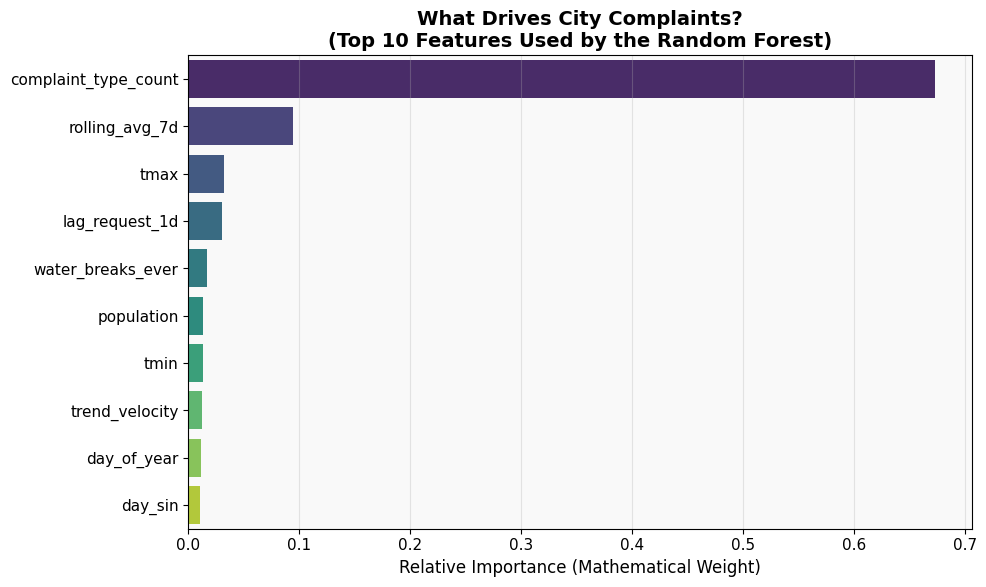

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

print("1. Initializing the Ultimate Tuned Model...\n")

# 1. Lock in your winning parameters
rf_tuned = RandomForestRegressor(
    n_estimators=100, 
    max_depth=15, 
    min_samples_split=10, 
    min_samples_leaf=4, 
    random_state=42, 
    n_jobs=-1
)

# 2. Get the Official Final Grades (using 5-Fold CV)
tscv = TimeSeriesSplit(n_splits=5)
r2_scores, mae_scores = [], []

print("🌲 Running Final Evaluation...")
for train_idx, test_idx in tscv.split(X_final):
    X_train_fold, X_test_fold = X_final.iloc[train_idx], X_final.iloc[test_idx]
    y_train_fold, y_test_fold = y_final_log.iloc[train_idx], y_final_log.iloc[test_idx]
    
    rf_tuned.fit(X_train_fold, y_train_fold)
    preds_log = rf_tuned.predict(X_test_fold)
    
    r2_scores.append(r2_score(y_test_fold, preds_log))
    mae_scores.append(mean_absolute_error(np.expm1(y_test_fold), np.expm1(preds_log)))

print("\n" + "="*40)
print("🏆 OFFICIAL FINAL GRADES (TUNED) 🏆")
print("="*40)
print(f"Average R²:  {np.mean(r2_scores):.4f}")
print(f"Average MAE: {np.mean(mae_scores):.2f} complaints")
print("="*40)

# 3. Extract Business Insights (Feature Importance)
print("\nExtracting Model Insights...")
# Train one last time on the ENTIRE dataset to see the big picture
rf_tuned.fit(X_final, y_final_log)

# Pull the importances and map them to column names
importances = rf_tuned.feature_importances_
feature_names = X_final.columns
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False).head(10) # Top 10

# 4. Plot the Insights
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title("What Drives City Complaints?\n(Top 10 Features Used by the Random Forest)", fontsize=14, fontweight='bold')
plt.xlabel("Relative Importance (Mathematical Weight)", fontsize=12)
plt.ylabel("")
plt.tight_layout()
plt.savefig("plot_15_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()

## Step 8 — Random forest Model ---- Compare with linear regression 

We train the following models and evaluate each honestly using Time-Series Cross Validation:

| Model | Type | Key Idea |
|---|---|---|
| Ridge Regression | Linear | Penalises large coefficients to prevent overfitting |
| Lasso Regression | Linear | Like Ridge, but can shrink some features to zero (automatic selection) |
| Random Forest | Tree ensemble | Many decision trees vote together — robust to noise |

Each model is evaluated using:
- **R2 Score** — how much of the variation in complaints does the model explain? (1.0 = perfect, 0 = useless)
- **MAE** — on average, how many complaints off is the prediction?
- **RMSE** — similar to MAE but penalises big errors more heavily

1. Initiating Final Step 8: The Grand Tournament...

Evaluating Ridge Regression (Linear)...
Evaluating Lasso Regression (Linear)...
Evaluating Tuned Random Forest...

🏆 STEP 8: FINAL EVALUATION LEADERBOARD 🏆


,Model,R2 Score,MAE,RMSE
0,Tuned Random Forest,0.553750,1.566534,4.433655
1,Lasso Regression (Linear),0.508739,14.847436,2154.568272
2,Ridge Regression (Linear),0.424565,10.941152,1506.933738



Generating Final Prediction vs Actual Dashboard...


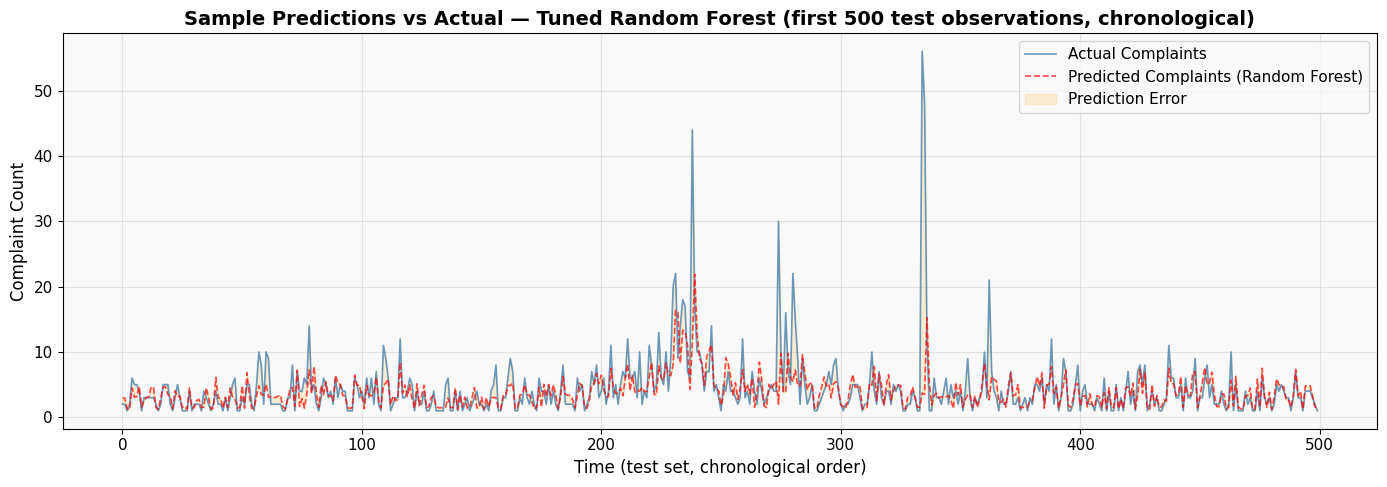

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

print("1. Initiating Final Step 8: The Grand Tournament...\n")

# 1. Define the Final Competitors (Using your Tuned settings for RF!)
models_to_test = {
    "Ridge Regression (Linear)": Ridge(alpha=1.0),
    "Lasso Regression (Linear)": Lasso(alpha=0.01),
    "Tuned Random Forest": RandomForestRegressor(
        n_estimators=100, 
        max_depth=15, 
        min_samples_split=10, 
        min_samples_leaf=4, 
        random_state=42, 
        n_jobs=-1
    )
}

tscv = TimeSeriesSplit(n_splits=5)
final_results = []

# We will save the actuals and predictions from the Random Forest's final fold for the chart
rf_final_actuals = None
rf_final_preds = None

for name, model in models_to_test.items():
    print(f"Evaluating {name}...")
    
    r2_folds, mae_folds, rmse_folds = [], [], []
    
    # Using your clean, winning dataset (X_final, y_final_log)
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_final)):
        X_train_fold, X_test_fold = X_final.iloc[train_idx], X_final.iloc[test_idx]
        y_train_fold, y_test_fold = y_final_log.iloc[train_idx], y_final_log.iloc[test_idx]
        
        # Train & Predict (Log Scale)
        model.fit(X_train_fold, y_train_fold)
        preds_log = model.predict(X_test_fold)
        
        # Reverse Log for actual metrics
        preds_actual = np.expm1(preds_log)
        y_actual = np.expm1(y_test_fold)
        
        # Calculate Metrics
        r2 = r2_score(y_test_fold, preds_log) # R2 is calculated on the log variance
        mae = mean_absolute_error(y_actual, preds_actual)
        rmse = np.sqrt(mean_squared_error(y_actual, preds_actual))
        
        r2_folds.append(r2)
        mae_folds.append(mae)
        rmse_folds.append(rmse)
        
        # If this is our Tuned Random Forest and the last fold, save data for the chart
        if name == "Tuned Random Forest" and fold == 4:
            rf_final_actuals = y_actual.values
            rf_final_preds = preds_actual
            
    final_results.append({
        "Model": name,
        "R2 Score": np.mean(r2_folds),
        "MAE": np.mean(mae_folds),
        "RMSE": np.mean(rmse_folds)
    })

# 2. Print the Formal Table
print("\n" + "="*60)
print("🏆 STEP 8: FINAL EVALUATION LEADERBOARD 🏆")
print("="*60)
results_df = pd.DataFrame(final_results).sort_values(by="R2 Score", ascending=False).reset_index(drop=True)
display(results_df)

# 3. Generate the Final Dashboard Plot 
print("\nGenerating Final Prediction vs Actual Dashboard...")
fig, ax5 = plt.subplots(figsize=(14, 5))

# We look at the first 500 test observations from the final fold
n_show = min(500, len(rf_final_actuals))
idx_show = np.arange(n_show)

ax5.plot(idx_show, rf_final_actuals[:n_show], color='steelblue', linewidth=1.2,
         alpha=0.8, label='Actual Complaints')
ax5.plot(idx_show, rf_final_preds[:n_show], color='red', linewidth=1.2,
         alpha=0.7, linestyle='--', label='Predicted Complaints (Random Forest)')

ax5.fill_between(idx_show, rf_final_actuals[:n_show], rf_final_preds[:n_show],
                 alpha=0.15, color='orange', label='Prediction Error')

ax5.set_title("Sample Predictions vs Actual — Tuned Random Forest (first 500 test observations, chronological)", fontsize=14)
ax5.set_xlabel("Time (test set, chronological order)", fontsize=12)
ax5.set_ylabel("Complaint Count", fontsize=12)
ax5.legend(fontsize=11)

plt.tight_layout()
plt.savefig("plot_16_final_dashboard_tuned.png", dpi=150, bbox_inches='tight')
plt.show()